# 05. Multilayer Perceptron (PyTorch)

MLP chọn cấu hình và số epoch bằng một bộ chia nội bộ nằm trong Train, sau đó fit lại trên toàn bộ Train. Validation chung dùng để chấm mô hình đã chốt.

| Giai đoạn | Dữ liệu | Quyết định |
|---|---|---|
| Tuning | 2.476 mẫu học và 620 mẫu dừng sớm từ fold đầu tiên trong Train | Chọn cấu hình và số epoch |
| Fit lại | Toàn bộ 3.096 mẫu Train | Học bộ tiền xử lý và MLP mới với số epoch đã chốt |
| Validation | 664 mẫu Validation chung | Tính metric và phân tích lỗi của mô hình đã lưu |

Các bảng tuning và đường học dùng tên **nội bộ** để phân biệt với Validation chung. Bộ chia nội bộ lấy sẵn từ fold đầu tiên trong `splits.json`. Tập Test dành cho bước đánh giá cuối của nhóm.

## Mở dữ liệu

Chọn kernel Python đã cài các thư viện trong `requirements.txt`.

In [1]:
import copy
import hashlib
import json
import sys
import time
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

# Tìm thư mục gốc để notebook đọc đúng file, kể cả khi kernel chạy từ thư mục con.
current = Path.cwd().resolve()
root = next(
    (folder for folder in (current, *current.parents)
     if (folder / "common/preprocessing.py").is_file()),
    None,
)
if root is None:
    raise FileNotFoundError("Mở thư mục student-dropout-prediction trong VS Code rồi chạy notebook.")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from common.preprocessing import FEATURE_COLUMNS, LABELS, TARGET, make_preprocessor
from common.metrics import (
    DROPOUT_LABEL, SUMMARY_COLUMNS, confusion_frame, evaluate, per_class_frame, summary_frame,
)

data_path = root / "data/raw/data.csv"
split_path = root / "data/splits/splits.json"
# File UCI ngăn cột bằng dấu chấm phẩy. Xóa khoảng trắng thừa quanh tên cột.
data = pd.read_csv(data_path, sep=";", encoding="utf-8-sig")
data.columns = data.columns.str.strip()

# Thống nhất ký tự xuống dòng trước khi tính mã nhận diện CSV trên Windows và Linux.
csv_bytes = data_path.read_bytes().replace(b"\r\n", b"\n")
data_hash = hashlib.sha256(csv_bytes).hexdigest()

table_dir = root / "reports/tables/mlp"
figure_dir = root / "reports/figures/mlp"
artifact_dir = root / "artifacts"
for folder in (table_dir, figure_dir, artifact_dir):
    folder.mkdir(parents=True, exist_ok=True)

## 1. Bộ chia chung và bộ chia nội bộ

Chỉ số trong `splits.json` là vị trí dòng trong CSV gốc, tính từ 0. Kiểm tra chỉ số hợp lệ, dòng trùng, độ bao phủ và giao nhau của cả ba tập trước khi lấy dữ liệu.

MLP dùng **phần học và phần chấm của fold đầu tiên** làm bộ chia nội bộ. Fold này đã được nhóm tạo phân tầng và lưu cố định. Tỉ lệ khoảng 80/20 trong Train xuất phát từ cách chia 5 fold. Đây là một lần giữ riêng dữ liệu để chọn cấu hình. Trong notebook này MLP chỉ dùng fold đầu tiên.

In [2]:
if not split_path.is_file():
    raise FileNotFoundError("Chạy 00_prepare_data.ipynb để tạo bộ chia.")
split = json.loads(split_path.read_text(encoding="utf-8"))
if split["sha256"] != data_hash or split["n_rows"] != len(data):
    raise ValueError("CSV hiện tại khác bản dùng để tạo bộ chia.")
split_hash = hashlib.sha256(split_path.read_bytes().replace(b"\r\n", b"\n")).hexdigest()


def checked_rows(rows, name):
    # Chặn chỉ số âm, dòng lặp và vị trí nằm ngoài CSV trước khi dùng iloc.
    if not isinstance(rows, list) or not rows:
        raise ValueError(f"{name} phải là danh sách chỉ số có dữ liệu.")
    if any(type(row) is not int or not 0 <= row < len(data) for row in rows):
        raise ValueError(f"{name} chứa chỉ số dòng không hợp lệ.")
    if len(rows) != len(set(rows)):
        raise ValueError(f"{name} chứa chỉ số dòng bị lặp.")
    return rows


SEED = split["seed"]
train_rows = checked_rows(split["train"], "Train")
validation_rows = checked_rows(split["validation"], "Validation")
test_rows = checked_rows(split["test"], "Test")
all_rows = train_rows + validation_rows + test_rows
if len(all_rows) != len(set(all_rows)) or set(all_rows) != set(range(len(data))):
    raise ValueError("Train, Validation và Test phải tách rời và bao phủ CSV.")

# Số 1 lấy fold đầu tiên theo quy tắc cố định trước khi tuning.
INTERNAL_FOLD = 1
internal_fold = split["folds"][INTERNAL_FOLD - 1]
fit_rows = checked_rows(internal_fold["train"], "Phần học nội bộ")
stop_rows = checked_rows(internal_fold["validation"], "Phần dừng sớm nội bộ")
if set(fit_rows) & set(stop_rows) or set(fit_rows + stop_rows) != set(train_rows):
    raise ValueError("Hai phần nội bộ phải tách rời và tạo thành đúng tập Train.")

X = data.loc[:, list(FEATURE_COLUMNS)]
y = data[TARGET]
if y.isna().any() or not y.isin(LABELS).all():
    raise ValueError("CSV có nhãn bị thiếu hoặc nằm ngoài ba lớp đã thống nhất.")
if any(set(y.iloc[rows]) != set(LABELS) for rows in (fit_rows, stop_rows)):
    raise ValueError("Mỗi phần nội bộ phải có đủ ba lớp.")

print(f"Train {len(train_rows):,} mẫu, Validation chung {len(validation_rows):,} mẫu")
print(f"Fold nội bộ {INTERNAL_FOLD}, học {len(fit_rows):,} mẫu, dừng sớm {len(stop_rows):,} mẫu")
display(pd.DataFrame({
    "học nội bộ": y.iloc[fit_rows].value_counts().reindex(LABELS),
    "dừng sớm nội bộ": y.iloc[stop_rows].value_counts().reindex(LABELS),
}).rename_axis("Target"))

Train 3,096 mẫu, Validation chung 664 mẫu
Fold nội bộ 1, học 2,476 mẫu, dừng sớm 620 mẫu


,học nội bộ,dừng sớm nội bộ
Target,,
Dropout,796,199
Enrolled,444,112
Graduate,1236,309


## 2. Tiền xử lý cho tuning

`make_preprocessor(scale_numeric=True)` chuẩn hóa cột số, one-hot cột phân loại và giữ cột nhị phân ở dạng 0/1. Lúc tuning, bộ xử lý chỉ fit trên **2.476 mẫu học nội bộ**, rồi transform 620 mẫu dừng sớm.

Sau khi chốt cấu hình, tạo một bộ xử lý mới và fit trên toàn bộ Train. Cách này giữ phần dừng sớm ngoài việc tính trung bình, độ lệch chuẩn và các thống kê tiền xử lý trong giai đoạn tuning. [Hướng dẫn giữ riêng dữ liệu khi tiền xử lý](https://scikit-learn.org/stable/modules/cross_validation.html#data-transformation-with-held-out-data)

In [3]:
import joblib
import sklearn

# Dùng chung một bộ xử lý đã fit trên phần học nội bộ cho cả 36 lượt tuning.
tuning_preprocessor = make_preprocessor(scale_numeric=True).fit(X.iloc[fit_rows])
X_fit = tuning_preprocessor.transform(X.iloc[fit_rows]).astype(np.float32)
X_stop = tuning_preprocessor.transform(X.iloc[stop_rows]).astype(np.float32)

LABEL_TO_CODE = {label: code for code, label in enumerate(LABELS)}
# Sao chép mảng nhãn để tensor có vùng nhớ ghi được; giữ nguyên nhãn và thứ tự mẫu.
y_fit = y.iloc[fit_rows].map(LABEL_TO_CODE).to_numpy(dtype=np.int64, copy=True)
y_stop = y.iloc[stop_rows].map(LABEL_TO_CODE).to_numpy(dtype=np.int64, copy=True)
print(f"scikit-learn {sklearn.__version__}")
print(f"{len(FEATURE_COLUMNS)} cột gốc thành {X_fit.shape[1]} đặc trưng khi tuning.")

scikit-learn 1.9.1
36 cột gốc thành 226 đặc trưng khi tuning.


## 3. Mô hình và vòng huấn luyện nội bộ

Mạng gồm các khối `Linear → ReLU → Dropout`, kết thúc bằng ba logit. `CrossEntropyLoss` nhận trực tiếp logit. `AdamW` cập nhật trọng số theo từng mini-batch.

Sau mỗi epoch, chấm **620 mẫu dừng sớm nội bộ** bằng hàm metric chung. Giữ trọng số của epoch có Macro-F1 cao nhất. Chờ tối đa 30 epoch liên tiếp thiếu cải thiện và đặt trần 300 epoch. Hai mức này kế thừa cấu hình chạy ban đầu để có giới hạn thời gian và cho mô hình cơ hội cải thiện qua các epoch dao động.

Nếu dùng `balanced`, tính trọng số lớp từ nhãn của phần học nội bộ. Loss trung bình của mỗi batch được nhân lại với tổng trọng số mẫu trong batch trước khi cộng thành loss cả epoch. Đây là mẫu số mà PyTorch dùng cho cross-entropy có trọng số. [Cách tính CrossEntropyLoss](https://docs.pytorch.org/docs/2.15/generated/torch.nn.CrossEntropyLoss.html)

In [4]:
import torch
from torch import nn

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MAX_EPOCHS = 300
PATIENCE = 30
# Dữ liệu nhỏ, một luồng CPU giảm chi phí điều phối giữa các phép nhân ma trận nhỏ.
torch.set_num_threads(1)


class MLP(nn.Module):
    def __init__(self, n_features, hidden_sizes, dropout, n_classes=len(LABELS)):
        super().__init__()
        layers = []
        width = n_features
        for size in hidden_sizes:
            layers.extend([nn.Linear(width, size), nn.ReLU(), nn.Dropout(dropout)])
            width = size
        layers.append(nn.Linear(width, n_classes))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)


def balanced_weights(labels):
    counts = np.bincount(labels, minlength=len(LABELS))
    return torch.tensor(len(labels) / (len(LABELS) * counts), dtype=torch.float32)


def set_seed(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


@torch.no_grad()
def predict_codes(model, features):
    model.eval()
    logits = model(features)
    return logits.argmax(dim=1).cpu().numpy(), logits


def fit_epoch(model, optimizer, loss_fn, features, targets, batch_size, generator):
    # Bộ sinh riêng giúp thứ tự batch được tái lập theo seed.
    model.train()
    order = torch.randperm(len(targets), generator=generator).to(features.device)
    weighted_loss = 0.0
    total_weight = 0.0
    for start in range(0, len(order), batch_size):
        batch = order[start:start + batch_size]
        optimizer.zero_grad()
        loss = loss_fn(model(features[batch]), targets[batch])
        loss.backward()
        optimizer.step()

        # Cross-entropy có trọng số chia cho tổng trọng số của các mẫu trong batch.
        batch_weight = len(batch)
        if loss_fn.weight is not None:
            batch_weight = loss_fn.weight[targets[batch]].sum().item()
        weighted_loss += loss.item() * batch_weight
        total_weight += batch_weight
    return weighted_loss / total_weight


Xt_fit = torch.from_numpy(X_fit).to(DEVICE)
yt_fit = torch.from_numpy(y_fit).to(DEVICE)
Xt_stop = torch.from_numpy(X_stop).to(DEVICE)
yt_stop = torch.from_numpy(y_stop).to(DEVICE)


def train_mlp(config, seed):
    set_seed(seed)
    model = MLP(X_fit.shape[1], config["hidden_sizes"], config["dropout"]).to(DEVICE)
    weights = balanced_weights(y_fit).to(DEVICE) if config["class_weight"] == "balanced" else None
    loss_fn = nn.CrossEntropyLoss(weight=weights)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=config["lr"], weight_decay=config["weight_decay"],
    )
    generator = torch.Generator().manual_seed(seed)
    history = []
    best = {"macro_f1": -1.0}
    epochs_without_gain = 0
    for epoch in range(1, MAX_EPOCHS + 1):
        train_loss = fit_epoch(
            model, optimizer, loss_fn, Xt_fit, yt_fit, config["batch_size"], generator,
        )
        # Chỉ chấm phần dừng sớm nằm trong Train để chọn epoch.
        predicted, logits = predict_codes(model, Xt_stop)
        result = evaluate(y_stop, predicted)
        history.append({
            "epoch": epoch, "train_loss": train_loss,
            "internal_loss": loss_fn(logits, yt_stop).item(),
            "internal_macro_f1": result["macro_f1"],
            "internal_accuracy": result["accuracy"],
        })
        if result["macro_f1"] > best["macro_f1"]:
            best = {
                "macro_f1": result["macro_f1"], "epoch": epoch, "result": result,
                "state_dict": copy.deepcopy(model.state_dict()),
            }
            epochs_without_gain = 0
        else:
            epochs_without_gain += 1
            if epochs_without_gain >= PATIENCE:
                break
    model.load_state_dict(best["state_dict"])
    return model, best, pd.DataFrame(history)


print(f"torch {torch.__version__} trên {DEVICE}")

torch 2.15.0+cpu trên cpu


## 4. Thử cấu hình trên phần nội bộ của Train

Giữ lưới 12 cấu hình của nhánh MLP ban đầu để đo tác động của việc sửa quy trình chia dữ liệu. Mỗi cấu hình chạy với các seed 42, 43 và 44, tạo 36 lượt. Seed đầu lấy từ bộ chia chung, hai seed sau dùng để quan sát dao động khi khởi tạo và xáo batch.

| Thành phần | Giá trị thử | Mục đích |
|---|---|---|
| `hidden_sizes` | `(64,)`, `(128, 64)`, `(256, 128)` | So một tầng ẩn với hai mạng hai tầng có độ rộng tăng dần |
| `dropout` | 0.2, 0.4 | So hai mức ngẫu nhiên tắt 20% hoặc 40% nơ-ron khi học |
| `class_weight` | `none`, `balanced` | Kiểm tra ảnh hưởng của cân trọng số giữa các lớp |

`lr=0.001`, `weight_decay=0.0001` và `batch_size=64` tiếp tục dùng các mốc của thí nghiệm ban đầu. Phạm vi này là lựa chọn thực nghiệm của nhóm. Mỗi cấu hình được xếp theo **Macro-F1 nội bộ trung bình qua ba seed**, dùng giá trị đầy đủ. Nếu bằng nhau, ưu tiên độ lệch chuẩn thấp hơn, sau đó dùng thứ tự cấu hình.

In [5]:
import itertools

SEEDS = (SEED, SEED + 1, SEED + 2)
FIXED = {"lr": 1e-3, "weight_decay": 1e-4, "batch_size": 64}
grid = [
    {"hidden_sizes": hidden, "dropout": dropout, "class_weight": class_weight, **FIXED}
    for hidden, dropout, class_weight in itertools.product(
        [(64,), (128, 64), (256, 128)], [0.2, 0.4], ["none", "balanced"],
    )
]

runs = []
histories = {}
started = time.perf_counter()
for config_id, config in enumerate(grid):
    for seed in SEEDS:
        _, best, run_history = train_mlp(config, seed)
        histories[config_id, seed] = run_history
        runs.append({
            "config_id": config_id, "seed": seed,
            "best_epoch": best["epoch"], "epochs_run": len(run_history),
            **{f"internal_{metric}": best["result"][metric] for metric in SUMMARY_COLUMNS},
        })
    print(f"Đã chạy cấu hình {config_id + 1}/{len(grid)} qua {len(SEEDS)} seed.", flush=True)
tuning_seconds = time.perf_counter() - started
print(f"Hoàn tất {len(runs)} lượt tuning trong {tuning_seconds:.0f}s.")

config_frame = pd.DataFrame([
    {"config_id": config_id, "hidden_sizes": str(config["hidden_sizes"]),
     "dropout": config["dropout"], "class_weight": config["class_weight"]}
    for config_id, config in enumerate(grid)
]).set_index("config_id")
run_scores = config_frame.join(pd.DataFrame(runs).set_index("config_id")).reset_index()
run_scores.to_csv(table_dir / "config_runs.csv", index=False)

Đã chạy cấu hình 1/12 qua 3 seed.


Đã chạy cấu hình 2/12 qua 3 seed.


Đã chạy cấu hình 3/12 qua 3 seed.


Đã chạy cấu hình 4/12 qua 3 seed.


Đã chạy cấu hình 5/12 qua 3 seed.


Đã chạy cấu hình 6/12 qua 3 seed.


... (3 outputs left out)

Đã chạy cấu hình 10/12 qua 3 seed.


Đã chạy cấu hình 11/12 qua 3 seed.


Đã chạy cấu hình 12/12 qua 3 seed.


Hoàn tất 36 lượt tuning trong 211s.


In [6]:
search = (
    run_scores.groupby("config_id")
    .agg(
        internal_macro_f1_mean=("internal_macro_f1", "mean"),
        internal_macro_f1_std=("internal_macro_f1", "std"),
        internal_accuracy_mean=("internal_accuracy", "mean"),
        internal_dropout_recall_mean=("internal_dropout_recall", "mean"),
        internal_dropout_f2_mean=("internal_dropout_f2", "mean"),
        best_epoch_median=("best_epoch", "median"),
    )
)
# Chỉ làm tròn khi hiển thị để giữ thứ tự theo điểm đầy đủ.
search = (
    config_frame.join(search).reset_index()
    .sort_values(
        ["internal_macro_f1_mean", "internal_macro_f1_std", "config_id"],
        ascending=[False, True, True],
    )
    .set_index("config_id")
)
search.to_csv(table_dir / "config_search.csv")
display(search.round(4))

,hidden_sizes,dropout,class_weight,internal_macro_f1_mean,internal_macro_f1_std,internal_accuracy_mean,internal_dropout_recall_mean,internal_dropout_f2_mean,best_epoch_median
config_id,,,,,,,,,
1,"(64,)",0.2,balanced,0.7145,0.0021,0.7522,0.7320,0.7462,17.0
11,"(256, 128)",0.4,balanced,0.7144,0.0068,0.7581,0.7002,0.7251,4.0
3,"(64,)",0.4,balanced,0.7143,0.0037,0.7522,0.7370,0.7486,22.0
5,"(128, 64)",0.2,balanced,0.7120,0.0083,0.7559,0.7152,0.7336,8.0
7,"(128, 64)",0.4,balanced,0.7110,0.0058,0.7527,0.7387,0.7494,13.0
0,"(64,)",0.2,none,0.7054,0.0071,0.7645,0.7521,0.7587,25.0
9,"(256, 128)",0.2,balanced,0.7046,0.0033,0.7484,0.7002,0.7203,4.0
6,"(128, 64)",0.4,none,0.7021,0.0128,0.7613,0.7370,0.7460,22.0
2,"(64,)",0.4,none,0.7019,0.0068,0.7629,0.7521,0.7579,49.0


### Nhận xét

Trong 12 cấu hình, mạng **(64,)**, dropout **0.2** và trọng số lớp **balanced** có Macro-F1 nội bộ trung bình cao nhất, đạt **0,7145 ± 0,0021** qua ba seed. Cấu hình đứng sau đạt **0,7144**, chênh **0,0001** điểm. Độ lệch chuẩn mô tả dao động khi đổi seed trên cùng bộ chia nội bộ.

Ba lượt của cấu hình được chọn có epoch tốt nhất **[27, 14, 17]**. Nhóm lấy trung vị **17 epoch** để fit lại toàn bộ Train. Điểm nội bộ phục vụ lựa chọn cấu hình. Điểm trên Validation chung được tính sau lần fit lại.

## 5. Chốt cấu hình, số epoch và xem đường học nội bộ

Lấy cấu hình đứng đầu bảng tuning. Số epoch để fit lại toàn bộ Train là **trung vị của ba epoch tốt nhất** của cấu hình này. Ví dụ, nếu ba lượt chọn epoch 10, 14 và 25, thì fit lại 14 epoch. Trung vị giúp một lượt dừng rất sớm hoặc rất muộn có ảnh hưởng nhỏ hơn đến số epoch chốt.

Quy tắc này được đặt trước khi chạy. Khi fit lại trên nhiều mẫu hơn, mỗi epoch có nhiều batch hơn, nên số epoch chuyển sang là một quy tắc thực nghiệm. Bộ trọng số cuối được học mới từ toàn bộ Train với seed 42.

In [7]:
best_id = int(search.index[0])
best_config = grid[best_id]
chosen_runs = run_scores.loc[run_scores["config_id"].eq(best_id)].sort_values("seed")
final_epochs = int(chosen_runs["best_epoch"].median())

# Lấy lịch sử seed chung đã có trong tuning để vẽ, tránh chạy chọn lại epoch.
history = histories[best_id, SEED]
history.to_csv(table_dir / "history.csv", index=False)
internal_best_epoch = int(chosen_runs.loc[chosen_runs["seed"].eq(SEED), "best_epoch"].iloc[0])
print("Cấu hình được chọn")
display(pd.Series(best_config, name="giá trị"))
print(f"Ba epoch tốt nhất theo thứ tự seed {list(SEEDS)} là {chosen_runs['best_epoch'].tolist()}.")
print(f"Số epoch cố định để fit lại toàn bộ Train là {final_epochs}.")
print(f"Macro-F1 nội bộ qua ba seed {search.loc[best_id, 'internal_macro_f1_mean']:.4f} "
      f"± {search.loc[best_id, 'internal_macro_f1_std']:.4f}.")

Cấu hình được chọn


hidden_sizes       (64,)
dropout              0.2
class_weight    balanced
lr                 0.001
weight_decay      0.0001
batch_size            64
Name: giá trị, dtype: object

Ba epoch tốt nhất theo thứ tự seed [42, 43, 44] là [27, 14, 17].
Số epoch cố định để fit lại toàn bộ Train là 17.
Macro-F1 nội bộ qua ba seed 0.7145 ± 0.0021.


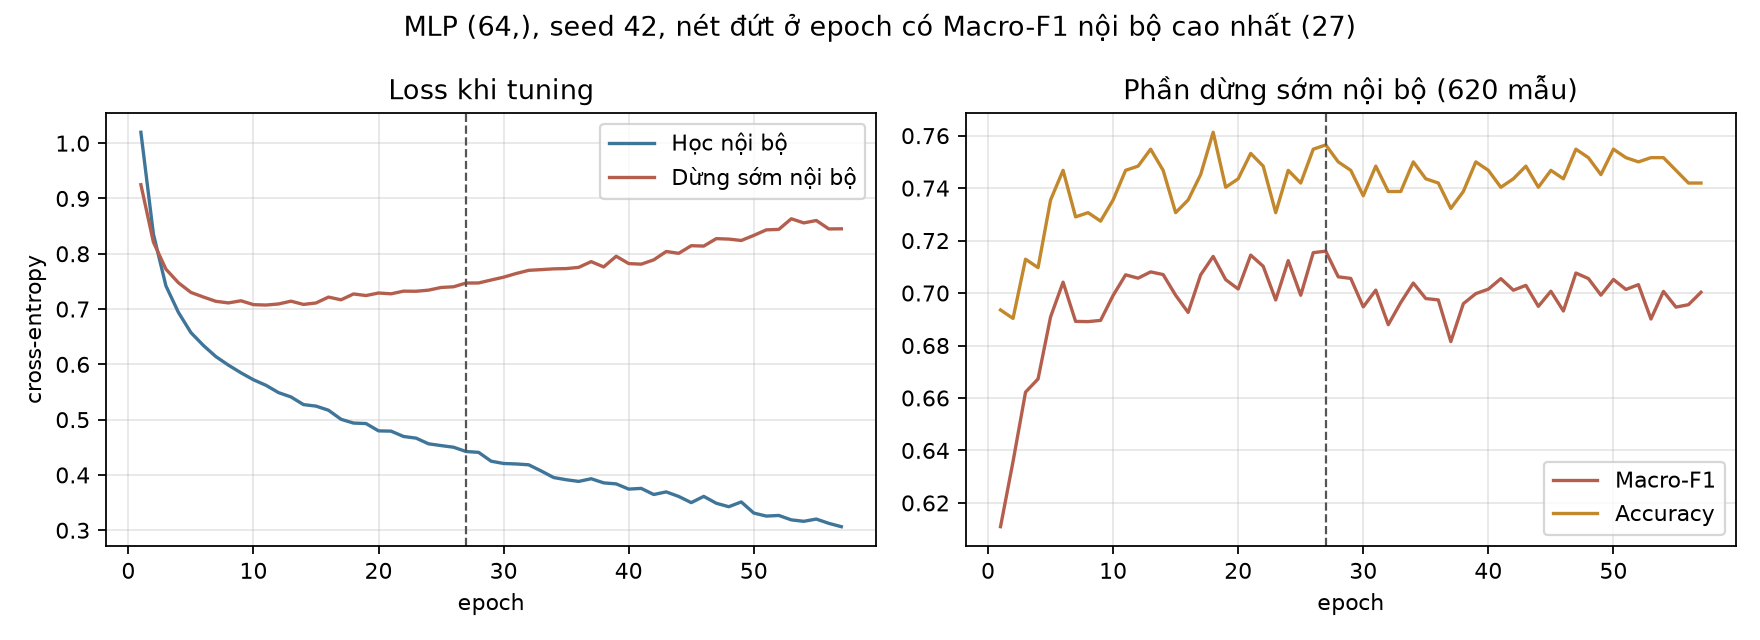

In [8]:
import matplotlib.pyplot as plt
from IPython.display import Image


def show_and_save(figure, filename):
    path = figure_dir / filename
    figure.tight_layout()
    figure.savefig(path, dpi=160)
    plt.close(figure)
    display(Image(filename=str(path)))


figure, (loss_ax, score_ax) = plt.subplots(1, 2, figsize=(11, 4))
loss_ax.plot(history["epoch"], history["train_loss"], color="#3F7599", label="Học nội bộ")
loss_ax.plot(history["epoch"], history["internal_loss"], color="#B45F4D", label="Dừng sớm nội bộ")
loss_ax.set(xlabel="epoch", ylabel="cross-entropy", title="Loss khi tuning")
loss_ax.legend()
score_ax.plot(history["epoch"], history["internal_macro_f1"], color="#B45F4D", label="Macro-F1")
score_ax.plot(history["epoch"], history["internal_accuracy"], color="#C3872C", label="Accuracy")
score_ax.set(xlabel="epoch", title=f"Phần dừng sớm nội bộ ({len(stop_rows)} mẫu)")
score_ax.legend()
for ax in (loss_ax, score_ax):
    ax.axvline(internal_best_epoch, color="#555555", linestyle="--", linewidth=1)
    ax.grid(alpha=0.3)
figure.suptitle(f"MLP {best_config['hidden_sizes']}, seed {SEED}, "
               f"nét đứt ở epoch có Macro-F1 nội bộ cao nhất ({internal_best_epoch})")
show_and_save(figure, "learning_curves.png")

### Nhận xét

Đường học này thuộc lượt tuning seed **42**, học trên **2.476 mẫu** và theo dõi **620 mẫu nội bộ**. Lượt chạy giữ epoch **27** theo Macro-F1 nội bộ và dừng ở epoch **57** sau thời gian chờ đã đặt.

Loss nội bộ thấp nhất là **0,7073** ở epoch **11**. Loss đầu và cuối lượt lần lượt là **0,9249** và **0,8451**. Loss học nội bộ đi từ **1,0197** xuống **0,3064**. Việc loss phần học tiếp tục giảm trong khi loss giữ riêng tăng về cuối là dấu hiệu overfit. Macro-F1 và cross-entropy đo hai khía cạnh khác nhau nên epoch có loss thấp nhất có thể khác epoch có Macro-F1 cao nhất.

Checkpoint cuối được khởi tạo mới và học **17 epoch trên 3.096 mẫu Train**. Lịch sử của lần fit này nằm trong `final_history.csv`.

## 6. Fit lại trên toàn bộ Train và lưu mô hình

Tạo bộ tiền xử lý mới, fit trên 3.096 mẫu Train, rồi khởi tạo MLP mới với số cột sau xử lý tương ứng. Tính lại trọng số lớp từ toàn bộ Train và chạy đủ số epoch đã chốt ở mục 5.

Vòng lặp này ghi loss của Train. Sau khi hoàn tất mới chấm Validation ở mục 7. Checkpoint lưu cả trọng số, kiến trúc và số epoch đã chạy. Nạp lại bộ xử lý và checkpoint, rồi so dự đoán trên Train để kiểm tra file bàn giao.

In [9]:
# Fit lại bộ xử lý từ toàn bộ Train. Số cột one-hot có thể khác lúc tuning.
preprocessor = make_preprocessor(scale_numeric=True).fit(X.iloc[train_rows])
X_train = preprocessor.transform(X.iloc[train_rows]).astype(np.float32)
# Sao chép mảng nhãn để tensor có vùng nhớ ghi được; giữ nguyên nhãn và thứ tự mẫu.
y_train = y.iloc[train_rows].map(LABEL_TO_CODE).to_numpy(dtype=np.int64, copy=True)
Xt_train = torch.from_numpy(X_train).to(DEVICE)
yt_train = torch.from_numpy(y_train).to(DEVICE)

set_seed(SEED)
model = MLP(X_train.shape[1], best_config["hidden_sizes"], best_config["dropout"]).to(DEVICE)
weights = balanced_weights(y_train).to(DEVICE) if best_config["class_weight"] == "balanced" else None
loss_fn = nn.CrossEntropyLoss(weight=weights)
optimizer = torch.optim.AdamW(
    model.parameters(), lr=best_config["lr"], weight_decay=best_config["weight_decay"],
)
generator = torch.Generator().manual_seed(SEED)
final_history = []
for epoch in range(1, final_epochs + 1):
    # Chạy đúng số epoch đã chọn từ phần nội bộ của Train.
    train_loss = fit_epoch(
        model, optimizer, loss_fn, Xt_train, yt_train, best_config["batch_size"], generator,
    )
    final_history.append({"epoch": epoch, "train_loss": train_loss})
pd.DataFrame(final_history).to_csv(table_dir / "final_history.csv", index=False)

preprocessor_path = artifact_dir / "mlp_preprocessor.joblib"
checkpoint_path = artifact_dir / "mlp_best.pt"
joblib.dump(preprocessor, preprocessor_path)
torch.save({
    "state_dict": {name: tensor.detach().cpu() for name, tensor in model.state_dict().items()},
    "n_features": int(X_train.shape[1]),
    "hidden_sizes": list(best_config["hidden_sizes"]),
    "dropout": best_config["dropout"],
    "labels": list(LABELS),
    # Giữ khóa best_epoch để đoạn nạp checkpoint cũ vẫn đọc được số epoch cuối.
    "best_epoch": final_epochs,
    "trained_epochs": final_epochs,
    "epoch_selection": "median_internal_best_epochs",
}, checkpoint_path)

checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
reloaded = MLP(checkpoint["n_features"], checkpoint["hidden_sizes"], checkpoint["dropout"])
reloaded.load_state_dict(checkpoint["state_dict"])
reloaded_preprocessor = joblib.load(preprocessor_path)
train_features = torch.from_numpy(
    reloaded_preprocessor.transform(X.iloc[train_rows]).astype(np.float32)
)
if not np.array_equal(
    predict_codes(reloaded, train_features)[0], predict_codes(model, Xt_train)[0],
):
    raise ValueError("Checkpoint nạp lại cho dự đoán khác mô hình vừa fit.")
print(f"Đã fit {len(train_rows):,} mẫu Train trong {final_epochs} epoch và kiểm tra nạp lại.")
print(f"Đã lưu {checkpoint_path.relative_to(root)} và {preprocessor_path.relative_to(root)}.")

Đã fit 3,096 mẫu Train trong 17 epoch và kiểm tra nạp lại.
Đã lưu artifacts\mlp_best.pt và artifacts\mlp_preprocessor.joblib.


## 7. Điểm trên Validation chung

Nạp checkpoint và bộ tiền xử lý đã chốt để dự đoán 664 sinh viên Validation. Bảng `validation_summary.csv` có một dòng MLP để ghép với các nhánh khác. Bảng dự đoán giữ số dòng CSV gốc để có thể đối chiếu từng lỗi.

In [10]:
# Validation chung được đưa vào sau khi hoàn tất tuning và fit lại.
X_validation = reloaded_preprocessor.transform(X.iloc[validation_rows]).astype(np.float32)
features = torch.from_numpy(X_validation)
predicted_codes, validation_logits = predict_codes(reloaded, features)
predicted = np.asarray(LABELS)[predicted_codes]
y_validation = y.iloc[validation_rows]
validation_result = evaluate(y_validation, predicted)

validation_summary = summary_frame({"MLP": validation_result})
validation_summary.to_csv(table_dir / "validation_summary.csv")
validation_per_class = per_class_frame(validation_result)
validation_per_class.to_csv(table_dir / "validation_per_class.csv")
confusion = confusion_frame(validation_result)
confusion.to_csv(table_dir / "validation_confusion.csv")
probabilities = torch.softmax(validation_logits, dim=1).numpy()
predictions = pd.DataFrame({
    "row_index": validation_rows, "y_true": y_validation.to_numpy(), "y_pred": predicted,
})
for position, label in enumerate(LABELS):
    predictions[f"probability_{label}"] = probabilities[:, position]
predictions.to_csv(table_dir / "predictions_val.csv", index=False)

print(f"Validation chung có {validation_result['n_samples']:,} sinh viên.")
display(validation_summary.round(4))
display(validation_per_class.round(4))
display(confusion)

Validation chung có 664 sinh viên.


,accuracy,macro_f1,dropout_recall,dropout_precision,dropout_f2
model,,,,,
MLP,0.7108,0.6833,0.6995,0.8054,0.7184


,precision,recall,f1,f2,support
Dropout,0.8054,0.6995,0.7487,0.7184,213
Enrolled,0.3961,0.6891,0.5031,0.6003,119
Graduate,0.8860,0.7259,0.7980,0.7531,332


dự đoán,Dropout,Enrolled,Graduate
thực tế,,,
Dropout,149,50,14
Enrolled,20,82,17
Graduate,16,75,241


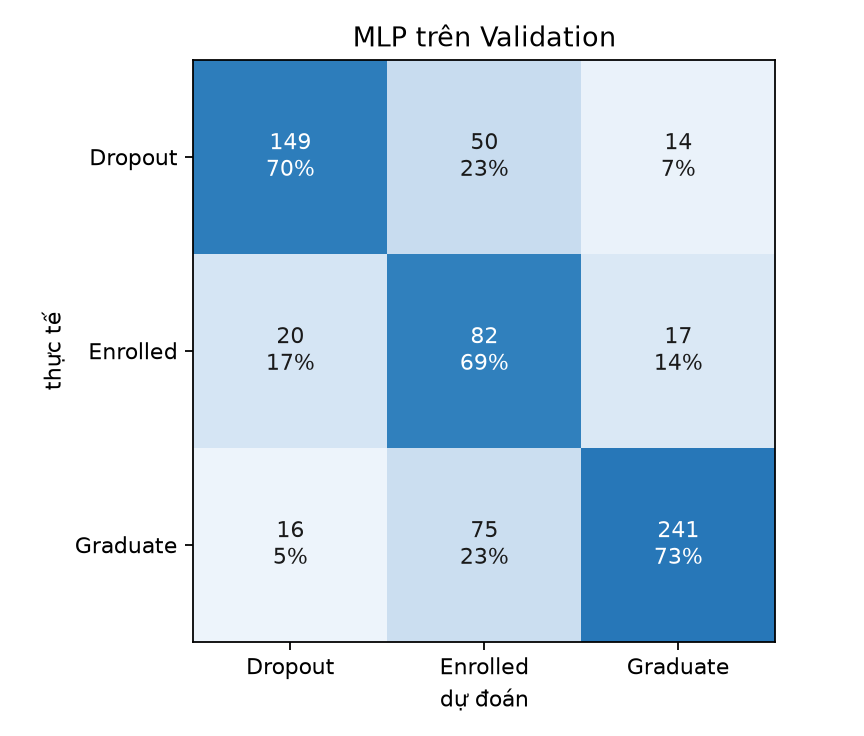

In [11]:
figure, ax = plt.subplots(figsize=(5.4, 4.6))
# Chia mỗi dòng cho support của dòng đó: màu thể hiện tỉ lệ trong từng lớp thực tế.
shares = confusion.to_numpy() / confusion.to_numpy().sum(axis=1, keepdims=True)
ax.imshow(shares, cmap="Blues", vmin=0, vmax=1)
for row in range(len(LABELS)):
    for column in range(len(LABELS)):
        count = confusion.to_numpy()[row, column]
        ax.text(column, row, f"{count}\n{shares[row, column]:.0%}",
                ha="center", va="center",
                color="white" if shares[row, column] > 0.5 else "#1A1A1A")
ax.set(xticks=range(len(LABELS)), yticks=range(len(LABELS)),
       xlabel="dự đoán", ylabel="thực tế", title="MLP trên Validation")
ax.set_xticklabels(LABELS)
ax.set_yticklabels(LABELS)
show_and_save(figure, "validation_confusion.png")

### Nhận xét

Checkpoint cuối đạt **Macro-F1 0,6833** và dự đoán đúng **472/664** sinh viên, tương ứng accuracy **71,08%**. Đây là kết quả trên Validation chung sau khi cấu hình và số epoch đã được chốt từ Train.

- **Dropout.** Nhận diện đúng **149/213** ca, recall **69,95%**, precision **80,54%** và F2 **0,7184**. Trong **64** ca bỏ sót, **50** bị gán Enrolled và **14** bị gán Graduate.
- **Lớp có F1 thấp nhất là Enrolled.** F1 đạt **0,5031**. Riêng Enrolled, mô hình nhận diện đúng **82/119** ca. Ma trận nhầm lẫn cho biết các cặp nhãn cần được phân tích trong báo cáo.

In [12]:
metadata = {
    "model": "MLP (PyTorch)",
    "created_utc": datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"),
    "notebook": "notebooks/models/mlp/05_mlp.ipynb",
    "torch_version": str(torch.__version__),
    "sklearn_version": sklearn.__version__,
    "device": str(DEVICE),
    "data_sha256": data_hash,
    "split_file_sha256": split_hash,
    "hash_line_endings": "lf",
    "split_seed": SEED,
    "labels": list(LABELS),
    "n_features_in": len(FEATURE_COLUMNS),
    "n_features_after_preprocess": int(X_train.shape[1]),
    "scale_numeric": True,
    "preprocessor": "artifacts/mlp_preprocessor.joblib",
    "best_config": {
        **{key: list(value) if isinstance(value, tuple) else value for key, value in best_config.items()},
        "optimizer": "AdamW", "seed": SEED,
    },
    "best_epoch": final_epochs,
    "trained_epochs": final_epochs,
    "epoch_selection": {
        "rule": "median_internal_best_epochs",
        "internal_best_epochs": chosen_runs["best_epoch"].astype(int).tolist(),
    },
    "config_search": {
        "scope": "outer_train_only",
        "internal_split": {
            "source": "data/splits/splits.json", "fold": INTERNAL_FOLD,
            "n_fit": len(fit_rows), "n_stop": len(stop_rows),
        },
        "n_features_after_preprocess": int(X_fit.shape[1]),
        "n_configs": len(grid), "seeds": list(SEEDS),
        "max_epochs": MAX_EPOCHS, "patience": PATIENCE,
        "early_stopping_metric": "internal_macro_f1",
        "selection_metric": "internal_macro_f1_mean",
        "config_id": best_id,
        "macro_f1_mean": float(search.loc[best_id, "internal_macro_f1_mean"]),
        "macro_f1_std": float(search.loc[best_id, "internal_macro_f1_std"]),
    },
    "n_train": len(train_rows),
    "n_validation": len(validation_rows),
    "validation": {metric: float(validation_result[metric]) for metric in SUMMARY_COLUMNS},
}
metadata_path = checkpoint_path.with_suffix(".json")
with metadata_path.open("w", encoding="utf-8", newline="\n") as output:
    json.dump(metadata, output, indent=2, ensure_ascii=False)
    output.write("\n")
print(f"Đã lưu {metadata_path.relative_to(root)}.")

Đã lưu artifacts\mlp_best.json.


## Bàn giao

MLP cuối có kiến trúc **232 → 64 → 3**, dropout **0.2**, trọng số lớp **balanced**, AdamW với learning rate **0.001**, weight decay **0.0001** và batch size **64**. Mô hình và bộ tiền xử lý được fit lại trên **3.096 mẫu Train** với seed **42**, chạy **17 epoch**.

Bảng chung lấy dòng MLP trong `validation_summary.csv`, Macro-F1 **0,6833**. Bảng tuning và độ lệch chuẩn ba seed mô tả phần nội bộ của Train. Tập Test dành cho bước tổng hợp sau khi nhóm khóa các mô hình.

| Sản phẩm | Đường dẫn |
|---|---|
| Bảng tuning nội bộ | `reports/tables/mlp/config_search.csv`, `config_runs.csv` |
| Đường học nội bộ và fit lại | `reports/tables/mlp/history.csv`, `final_history.csv` |
| Mô hình và thông tin cấu hình | `artifacts/mlp_best.pt`, `mlp_best.json` |
| Bộ tiền xử lý fit trên Train | `artifacts/mlp_preprocessor.joblib` |
| Kết quả Validation | `reports/tables/mlp/validation_summary.csv`, `validation_per_class.csv`, `validation_confusion.csv` |
| Dự đoán từng sinh viên | `reports/tables/mlp/predictions_val.csv` |
| Biểu đồ | `reports/figures/mlp/learning_curves.png`, `validation_confusion.png` |

Để dùng checkpoint ở notebook tổng hợp, dùng class `MLP` ở mục 3 rồi nạp mô hình bằng đoạn sau. `root` trỏ tới thư mục gốc của repo và `df` là DataFrame có các cột đầu vào.

```python
import joblib
import numpy as np
import torch
from common.preprocessing import FEATURE_COLUMNS

preprocessor = joblib.load(root / "artifacts/mlp_preprocessor.joblib")
checkpoint = torch.load(root / "artifacts/mlp_best.pt", map_location="cpu", weights_only=True)
model = MLP(checkpoint["n_features"], checkpoint["hidden_sizes"], checkpoint["dropout"])
model.load_state_dict(checkpoint["state_dict"])
model.eval()

# Dùng bộ xử lý đã lưu để biến đổi dữ liệu mới.
features = torch.from_numpy(preprocessor.transform(df[list(FEATURE_COLUMNS)]).astype(np.float32))
with torch.no_grad():
    codes = model(features).argmax(dim=1).numpy()
predicted_labels = np.asarray(checkpoint["labels"])[codes]
```